In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
purities = []
ari = []
anmi = []
for i in range(1, 9):
    df = pd.read_csv('./user_data_per_doc/{}.csv'.format(i))
    purities.append(df['purity'])
    ari.append(df['randIndex'])
    anmi.append(df['NMI'])

In [7]:
max_doc_labeled = 0
max_index = 0
min_doc_labeled = 1000
min_index = 0
for i in range(len(purities)):
    if len(purities[i]) > max_doc_labeled:
        max_doc_labeled = len(purities[i])
        max_index = i+1

    if len(purities[i]) < min_doc_labeled:
        min_doc_labeled = len(purities[i])
        min_index = i+1 

print(max_index)
print(max_doc_labeled)


2
100


In [8]:
print(min_index)
print(min_doc_labeled)

8
24


In [9]:
for i in range(len(purities)):
    print(len(purities[i]))

46
100
58
56
54
40
36
24


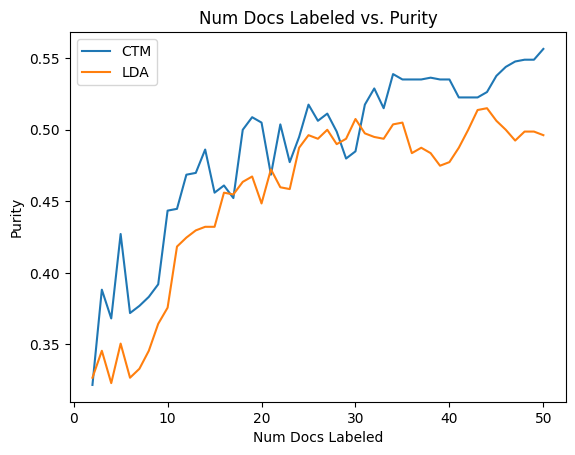

In [40]:
stop_point = 50
x_axis = [i+1 for i in range(1, stop_point)]
plt.plot(x_axis, purities[2][1:stop_point], label='CTM')
plt.plot(x_axis, purities[1][1:stop_point], label='LDA')
plt.legend()

# Optional: Add titles and labels
plt.title('Num Docs Labeled vs. Purity')
plt.xlabel('Num Docs Labeled')
plt.ylabel('Purity')

plt.show()

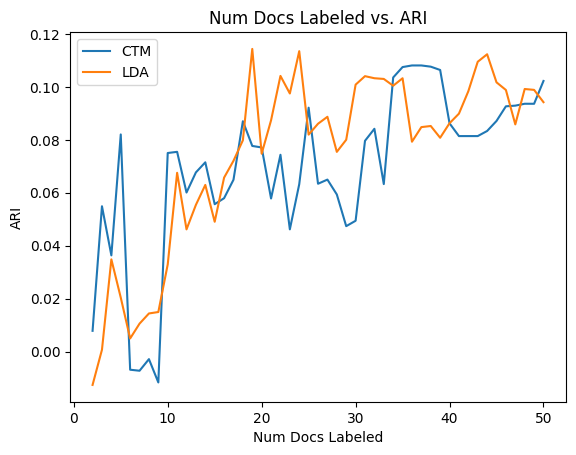

In [41]:
stop_point = 50
x_axis = [i+1 for i in range(1, stop_point)]
plt.plot(x_axis, ari[2][1:stop_point], label='CTM')
plt.plot(x_axis, ari[1][1:stop_point], label='LDA')
plt.legend()

# Optional: Add titles and labels
plt.title('Num Docs Labeled vs. ARI')
plt.xlabel('Num Docs Labeled')
plt.ylabel('ARI')

plt.show()

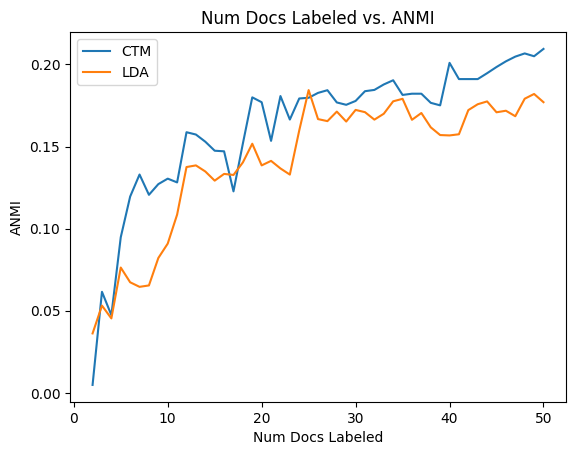

In [45]:
stop_point = 50
x_axis = [i+1 for i in range(1, stop_point)]
plt.plot(x_axis, anmi[2][1:stop_point], label='CTM')
plt.plot(x_axis, anmi[1][1:stop_point], label='LDA')
plt.legend()

# Optional: Add titles and labels
plt.title('Num Docs Labeled vs. ANMI')
plt.xlabel('Num Docs Labeled')
plt.ylabel('ANMI')

plt.show()

In [50]:
data = {
    'purity': [],
    'randIndex': [],
    'NMI': [],
    'numDocsLabeled': [],
    'group': []
}

In [51]:
group = 2
for i in range(1, stop_point):
    data['purity'].append(purities[group][i])
    data['randIndex'].append(ari[group][i])
    data['NMI'].append(anmi[group][i])
    data['numDocsLabeled'].append(i+1)
    data['group'].append('CTM')

In [52]:
group = 1
for i in range(1, stop_point):
    data['purity'].append(purities[group][i])
    data['randIndex'].append(ari[group][i])
    data['NMI'].append(anmi[group][i])
    data['numDocsLabeled'].append(i+1)
    data['group'].append('LDA')

In [53]:
new_df = pd.DataFrame(data)
# csv_file = './gender_pronouns/mistral_7b_generated_emails.csv'
csv_file = './resilience.csv'
new_df.to_csv(csv_file, index=False)